In [ ]:
import kagglehub
import os

In [ ]:
kagglehub.login()

In [ ]:
os.environ['KAGGLEHUB_CACHE'] = "./data"

In [ ]:
path = kagglehub.competition_download("multimodal-cancer-classification-challenge-2026")

100%|██████████| 737M/737M [00:11<00:00, 69.9MB/s]

Extracting files...


In [ ]:
!pip install -q timm albumentations
!pip install torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 22.9 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
from sklearn.model_selection import train_test_split
# from torchmetrics import
import gc
import cv2
import timm
import random

from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
print(os.listdir(path))

['sampleSubmission.csv', 'FL', 'train.csv', 'BF']


Visualizing samples with labels from train.csv:


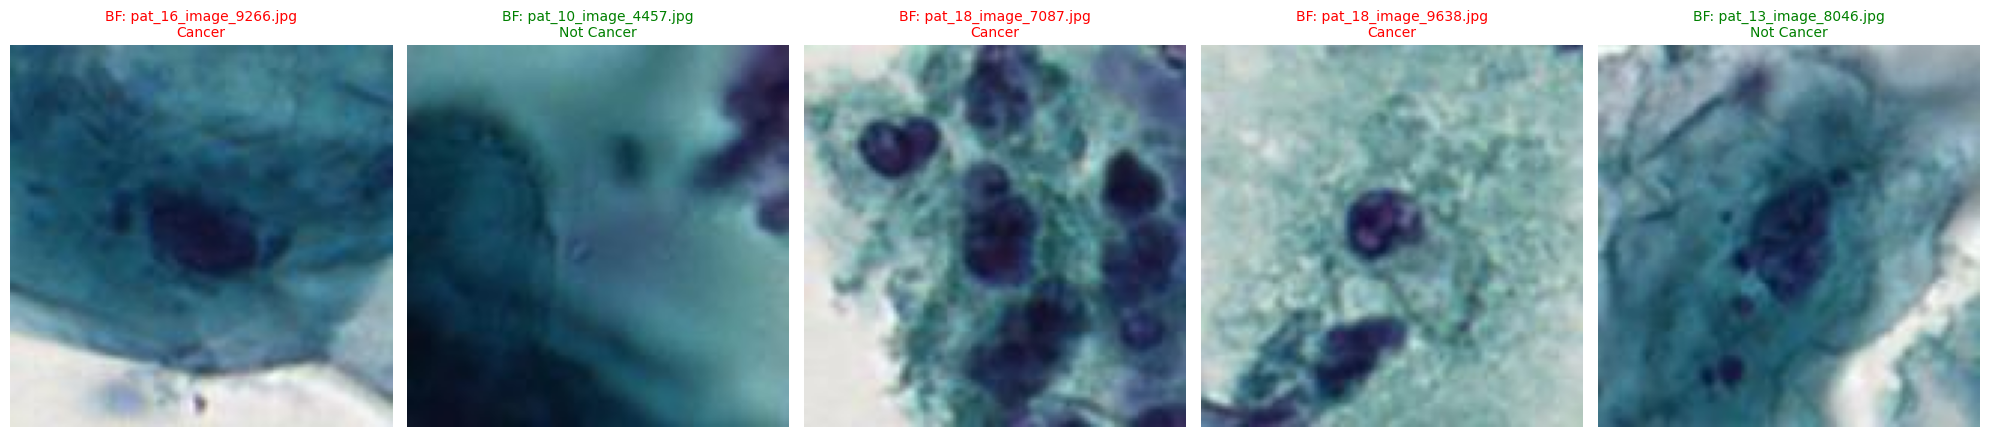

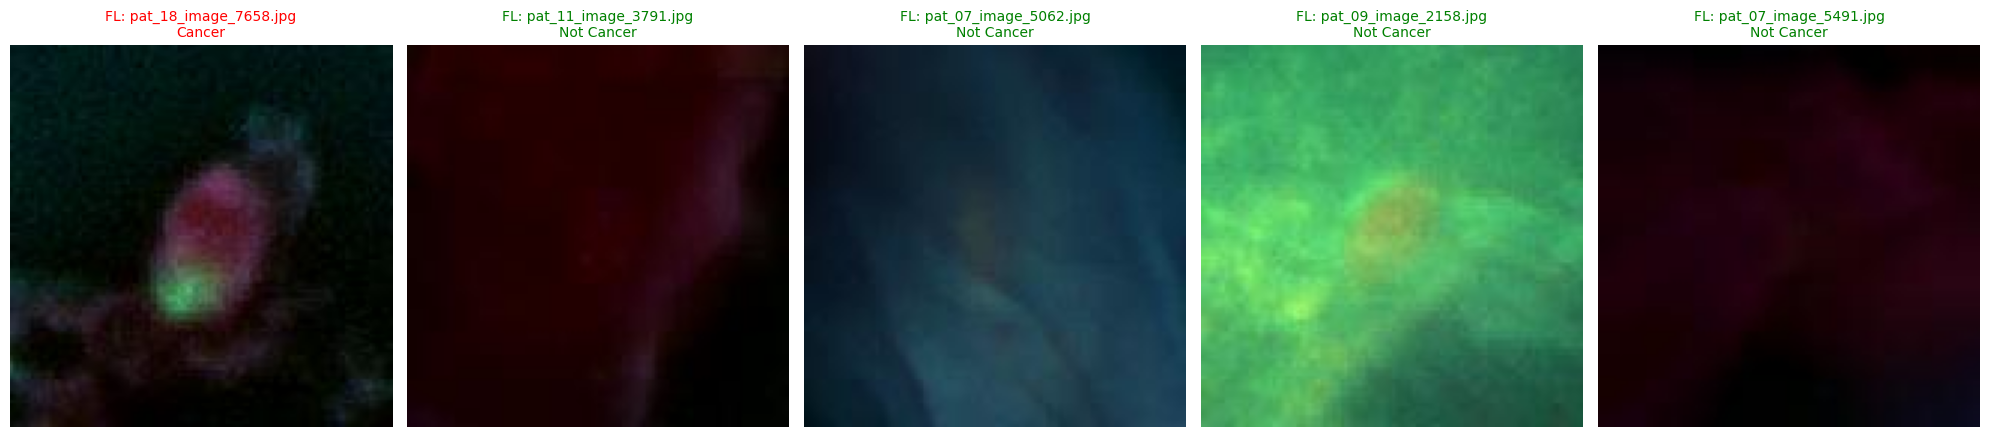

In [ ]:
# Load the latest labels from the competition directory
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Define paths for Bright Field and Fluorescence training images
BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')

# Mapping for human-readable titles
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

# Get lists of available image files
BF_Images_list = [f for f in os.listdir(BF_Images) if f.lower().endswith(('.jpg'))]
FL_Images_list = [f for f in os.listdir(FL_Images) if f.lower().endswith(('.jpg'))]

random.shuffle(BF_Images_list)
random.shuffle(FL_Images_list)

def plot_labeled_samples(img_list, base_path, title_prefix):
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))
    for i in range(5):
        img_name = img_list[i]
        img_path = os.path.join(base_path, img_name)
        img = cv2.imread(img_path)

        # Search for the diagnosis in the train_df based on filename
        match = train_df[train_df['Name'] == img_name]
        if not match.empty:
            label_val = match.iloc[0]['Diagnosis']
            label_text = diagnosis_map.get(label_val, 'Unknown')
        else:
            label_text = "Not Found in CSV"

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[i].imshow(img)
            title_color = 'red' if label_text == 'Cancer' else 'green' if label_text == 'Not Cancer' else 'black'
            ax[i].set_title(f"{title_prefix}: {img_name}\n{label_text}", color=title_color, fontsize=10)
        ax[i].axis("off")
    plt.tight_layout()
    plt.show()

print("Visualizing samples with labels from train.csv:")
plot_labeled_samples(BF_Images_list, BF_Images, "BF")
plot_labeled_samples(FL_Images_list, FL_Images, "FL")

In [ ]:
import re

# Extract Patient ID from the 'Name' column (e.g., 'pat_03_image_1.jpg' -> 'pat_03')
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Initialize GroupKFold
gkf = GroupKFold(n_splits=5)
train_df['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
    train_df.loc[val_idx, 'fold'] = fold

print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
print(f"Unique patients per fold check:\n{train_df.groupby('fold')['Patient'].nunique()}")

Fold distribution:
fold
0    30000
1    24302
4    20000
3    20000
2    20000
Name: count, dtype: int64
Unique patients per fold check:
fold
0    3
1    3
2    2
3    2
4    2
Name: Patient, dtype: int64


In [ ]:
class MultimodalCancerDataset(Dataset):
    def __init__(self, df, bf_dir, fl_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']
        label = torch.tensor(self.df.loc[idx, 'Diagnosis'], dtype=torch.long)

        # Load BF Image
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL Image
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            # Apply same transforms to both or handle separately
            # For now, we concatenate them to apply multimodal transforms
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']

            # Stack modalities: Shape (6, H, W) or handle as list
            return torch.cat([augmented_bf, augmented_fl], dim=0), label

        return (bf_img, fl_img), label

In [ ]:
transforms = A.Compose([
    A.Resize(128, 128),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Split into train/val for Fold 0
train_idx = train_df[train_df['fold'] != 0].index
valid_idx = train_df[train_df['fold'] == 0].index

train_ds = MultimodalCancerDataset(train_df.loc[train_idx], BF_Images, FL_Images, transform=transforms)
valid_ds = MultimodalCancerDataset(train_df.loc[valid_idx], BF_Images, FL_Images, transform=transforms)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples: {len(train_ds)}, Valid samples: {len(valid_ds)}")

Train samples: 84302, Valid samples: 30000


In [ ]:
train_transforms = A.Compose([
    A.Resize(128, 128),
    A.HorizontalFlip(p=0.2),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.2),
    # Fixed: Affine uses translate_percent instead of shift
    # A.Affine(translate_percent=(0, 0.0625), scale=(0.9, 1.1), rotate=(-45, 45), p=0.5),
    # A.OneOf([
    #     # Fixed: Changed std_range to small float values compatible with normalized images
    #     A.GaussNoise(std_range=(0.01, 0.05), p=1.0),
    #     A.GaussianBlur(blur_limit=(3, 7), p=1.0),
    # ], p=0.3),
    # A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), p=1.0),
        A.RandomGamma(gamma_limit=(80, 120), p=1.0),
        A.CLAHE(clip_limit=(1, 4), p=1.0),
        A.Sharpen(p=1.0),
    ], p=0.8),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(128, 128),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

train_ds.transform = train_transforms
valid_ds.transform = val_transforms

In [ ]:
class MultimodalModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0', pretrained=True):
        super(MultimodalModel, self).__init__()
        # Backbone for Bright Field modality
        self.backbone_bf = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        # Backbone for Fluorescence modality
        self.backbone_fl = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')

        # Get feature dimension
        num_features = self.backbone_bf.num_features

        # Fusion layer (Late Fusion)
        self.classifier = nn.Sequential(
            nn.Linear(num_features * 2, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1) # Output logit for Binary Classification
        )

    def forward(self, x):
        # x is expected to be (Batch, 6, H, W)
        # Split into BF (first 3 channels) and FL (last 3 channels)
        x_bf = x[:, :3, :, :]
        x_fl = x[:, 3:, :, :]

        feat_bf = self.backbone_bf(x_bf)
        feat_fl = self.backbone_fl(x_fl)

        # Concatenate features
        combined_features = torch.cat([feat_bf, feat_fl], dim=1)

        # Final classification
        logits = self.classifier(combined_features)
        return logits

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_late = MultimodalModel().to(device)
print(f"Model initialized on {device}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Model initialized on cuda


In [ ]:
from torchmetrics.classification import BinaryAUROC, BinaryAccuracy
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)

    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(device), labels.to(device).float().view(-1, 1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        auroc_metric.update(torch.sigmoid(outputs), labels.int())

    return total_loss / len(loader), auroc_metric.compute().item()

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    acc_metric = BinaryAccuracy().to(device)

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device).float().view(-1, 1)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.sigmoid(outputs)
            auroc_metric.update(probs, labels.int())
            acc_metric.update(probs, labels.int())

    return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

# Hyperparameters & Setup
# EPOCHS = 3
# learning_rate = 1e-4
# criterion = nn.BCEWithLogitsLoss()
# optimizer = Adam(model.parameters(), lr=learning_rate)

# for epoch in range(EPOCHS):
#     train_loss, train_auc = train_one_epoch(model, train_loader, optimizer, criterion, device)
#     val_loss, val_auc, val_acc = validate(model, valid_loader, criterion, device)



#     print(f"\nEpoch {epoch+1}/{EPOCHS}")
#     print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
#     print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

In [ ]:
EPOCHS = 10
learning_rate = 1e-4
criterion = nn.BCEWithLogitsLoss()
optimizer = Adam(model_late.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_late, train_loader, optimizer, criterion, device)
    val_loss, val_auc, val_acc = validate(model_late, valid_loader, criterion, device)

    scheduler.step(val_auc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_late.state_dict(), 'best_model_efficientB0_late.pth')
        print("*** Best Model Saved ***")

Validation: 100%|██████████| 469/469 [00:44<00:00, 10.51it/s]



Epoch 1/10
Train Loss: 0.1877 | Train AUC: 0.9730
Val Loss: 1.0015 | Val AUC: 0.9332 | Val Acc: 0.6504
Current LR: 0.0001
*** Best Model Saved ***


Validation: 100%|██████████| 469/469 [00:44<00:00, 10.63it/s]



Epoch 2/10
Train Loss: 0.1024 | Train AUC: 0.9918
Val Loss: 0.5427 | Val AUC: 0.9799 | Val Acc: 0.7895
Current LR: 0.0001
*** Best Model Saved ***


Validation: 100%|██████████| 469/469 [00:43<00:00, 10.69it/s]



Epoch 3/10
Train Loss: 0.0773 | Train AUC: 0.9953
Val Loss: 0.6624 | Val AUC: 0.9796 | Val Acc: 0.7417
Current LR: 0.0001


... (10 outputs left out)

Validation: 100%|██████████| 469/469 [00:44<00:00, 10.52it/s]



Epoch 9/10
Train Loss: 0.0226 | Train AUC: 0.9996
Val Loss: 0.9260 | Val AUC: 0.9766 | Val Acc: 0.7458
Current LR: 1.25e-05


Validation: 100%|██████████| 469/469 [00:44<00:00, 10.49it/s]


Epoch 10/10
Train Loss: 0.0208 | Train AUC: 0.9997
Val Loss: 1.0907 | Val AUC: 0.9712 | Val Acc: 0.7199
Current LR: 6.25e-06


In [ ]:
class MultimodalTestDataset(Dataset):
    def __init__(self, test_df, bf_dir, fl_dir, transform=None):
        self.df = test_df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']

        # Load BF
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']
            return torch.cat([augmented_bf, augmented_fl], dim=0), img_name

        return (bf_img, fl_img), img_name

# Load sample submission to get test file names
test_df = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))

# Note: Assuming test images are in 'BF/test' and 'FL/test'
BF_Test = os.path.join(path, 'BF', 'test')
FL_Test = os.path.join(path, 'FL', 'test')

test_ds = MultimodalTestDataset(test_df, BF_Test, FL_Test, transform=transforms)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)



In [ ]:
model_late.eval()
predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model_late(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

# Create submission dataframe
submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission_eff_late_fahim.csv', index=False)
print("Submission file saved as submission.csv")
display(submission.head())

Testing: 100%|██████████| 923/923 [01:23<00:00, 11.04it/s]


Submission file saved as submission.csv


,Name,Diagnosis
0,image_1.jpg,2.072243e-01
1,image_2.jpg,5.290153e-03
2,image_3.jpg,6.457302e-03
3,image_4.jpg,6.608910e-07
4,image_5.jpg,1.168790e-04
